## MQTT

In [ ]:
import paho.mqtt.client as mqtt
import json
import time
import multiprocessing


In [ ]:
DEVICE_NAME = "BLUE_LED"


In [ ]:
# Read the config file and get the values
with open('data/config.json', 'r', encoding='utf-8') as json_data_file:
    config = json.load(json_data_file)

mqtt_host = config['mqtt']['host']
username = config['mqtt']['username']
password = config['mqtt']['password']
topic = config['mqtt']['topic']
mqttc = mqtt.Client()
mqttc.username_pw_set(username, password)
mqttc.connect(mqtt_host, 1883, 60)


### Change State

In [ ]:
while True:

    change_state_message = {
        'origin': 'check_mqtt.ipynb',
        'messageType': 'change_state',
        'message': {
            'device_id': 'BLUE_LED',
            'state': input("Enter the state: ")
        }
    }
    match change_state_message['message']['state']:
        case 'ON':
            mqttc.publish(topic, json.dumps(change_state_message))
        case 'OFF':
            mqttc.publish(topic, json.dumps(change_state_message))
        case 'EXIT':
            print("Invalid state")
            break


### Check State

In [ ]:
current_state_message = {
    'origin': 'check_mqtt.ipynb',
    'messageType': 'current_state',
    'message': {
        'device_id': DEVICE_NAME,
    }
}

mqttc.publish(topic, json.dumps(current_state_message))


In [ ]:
kepp_alive_counter = 0
start_time = time.time()
def keep_alive():
    mqttc.publish(topic, json.dumps(
        {
            "origin": "check_mqtt.ipynb",
            "messageType": "keep_alive", 
            "message": {
                "keep_alive_counter": kepp_alive_counter,
                "uptime": time.time() - start_time
            }
        }
    ))
    kepp_alive_counter += 1
    time.sleep(50)

kepp_alive_process = multiprocessing.Process(target=keep_alive)
kepp_alive_process.start()


## QR-CODE GENERATOR

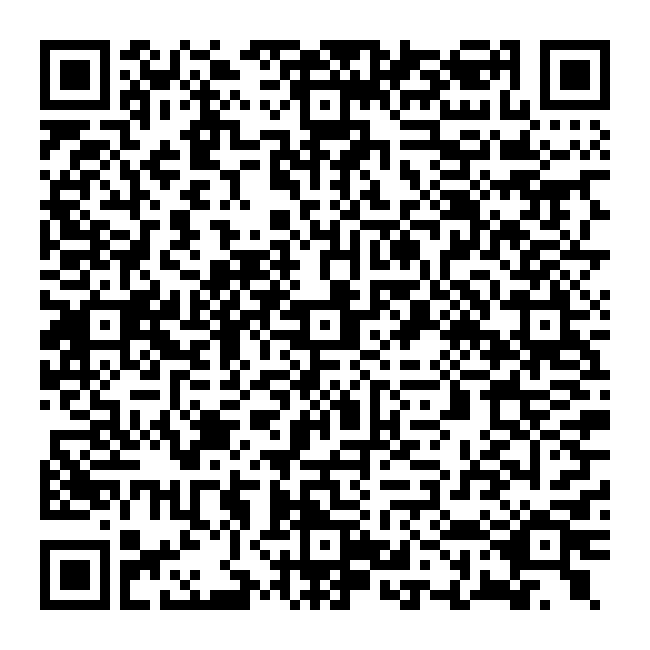

In [2]:
from IPython.display import display
import qrcode
import json

# Define the BLE connection information
ble_info = {
    "device_name": "Stapes_B0_B2_1C_A7_5E_C4",
    "service_uuid": "4fafc201-1fb5-459e-8fcc-c5c9c331914b",
    "config_characteristic_uuid": "beb5483e-36e1-4688-b7f5-ea07361b26a8",
    "version_characteristic_uuid": "82bf15cb-ce87-4696-9698-a68391599b5f"
}

# Convert the BLE information to a JSON string
ble_info_json = json.dumps(ble_info)

# Generate the QR code
qr = qrcode.QRCode(
    version=1,
    error_correction=qrcode.constants.ERROR_CORRECT_L,
    box_size=10,
    border=4,
)
qr.add_data(ble_info_json)
qr.make(fit=True)

# Create an image from the QR code
img = qr.make_image(fill='black', back_color='white')

# Display the QR code
display(img)

# Save the QR code as an image
img.save("generated_ble_qr_code.png")
